# Nash Support Enumeration

Two players prefer to coordinate, but they disagree about which coordinated outcome is best. Enumerating supports finds both pure equilibria and the mixed equilibrium.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Two payoff matrices

Each entry of the first matrix belongs to the row player. The second matrix gives the column player’s payoff at the same outcome.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import nashpy as nash


def incentives(A, B, p, q):
    row_gain = (A @ q).max() - p @ A @ q
    column_gain = (p @ B).max() - p @ B @ q
    return max(0.0, row_gain), max(0.0, column_gain)

## Check unilateral deviations

For each candidate, compare its expected payoff with the best pure deviation against the opponent’s fixed distribution.

Row [1. 0.], column [1. 0.] | payoffs (3.000, 1.000) | max gain 0
Row [0. 1.], column [0. 1.] | payoffs (1.000, 3.000) | max gain 0
Row [0.75 0.25], column [0.25 0.75] | payoffs (0.750, 0.750) | max gain 0
Equilibria found: 3


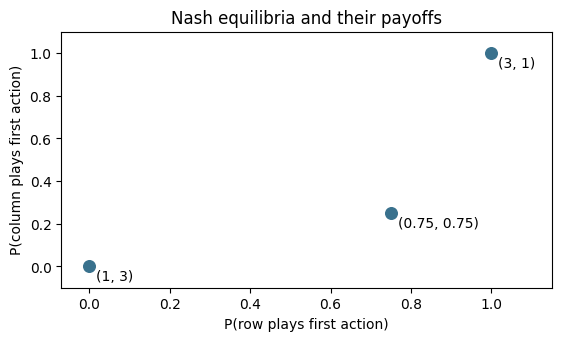

In [3]:
A = np.array([[3.0, 0.0], [0.0, 1.0]])
B = np.array([[1.0, 0.0], [0.0, 3.0]])
equilibria = list(nash.Game(A, B).support_enumeration())
fig, ax = plt.subplots(figsize=(5.5, 3.3), constrained_layout=True)
for p, q in equilibria:
    gains = incentives(A, B, p, q)
    print(
        f"Row {p.round(3)}, column {q.round(3)} | payoffs ({p@A@q:.3f}, {p@B@q:.3f}) | max gain {max(gains):.2g}"
    )
    assert max(gains) < 1e-8
    ax.scatter(p[0], q[0], s=70, color="#39718d")
    ax.annotate(
        f"({p@A@q:.2g}, {p@B@q:.2g})", (p[0], q[0]), xytext=(5, -10), textcoords="offset points"
    )
print(f"Equilibria found: {len(equilibria)}")
ax.set(
    xlabel="P(row plays first action)",
    ylabel="P(column plays first action)",
    title="Nash equilibria and their payoffs",
    xlim=(-0.07, 1.15),
    ylim=(-0.1, 1.1),
)
plt.show()

## Reading the result

The mixed equilibrium makes both players indifferent between the actions they use. The pure equilibria yield different divisions of the coordination benefit.

## References

[Nash, Equilibrium Points in N-Person Games (1950)](https://doi.org/10.1073/pnas.36.1.48)

[Nashpy, support enumeration](https://nashpy.readthedocs.io/en/stable/text-book/support-enumeration.html)